<a href="https://colab.research.google.com/github/240264-sudo/AI-ML-lab/blob/main/AI_ML_K_means_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cluster Labels:
[1 1 0 2 1 2 0 2 0 0 0 2 0 0 1 0 1 2 0 0 0 0 2 1 0 1 1 2 2 0 0 0 1 0 1 0 1
 2 1 2 2 0 1 2 0 0 1 2 1 2 2 1 1 0 1 2 1 0 2 0 1 2 2 1 1 2 2 1 1 0 2 1 1 0
 0 1 1 2 0 2 0 0 1 0 2 1 1 0 2 0 1 0 1 0 0 1 1 0 1 1 2 0 2 0 0 0 0 0 2 1 2
 0 0 0 0 2 1 2 1 2 2 2 0 1 1 1 1 0 1 1 0 0 0 0 0 2 2 1 0 1 0 0 1 0 2 2 2 0
 2 0 0 1 2 1 0 2 2 1 1 0 0 1 1 1 0 1 2 0 0 0 0 0 2 0 2 2 2 0 2 2 1 0 1 2 2
 1 2 0 2 2 1 1 2 1 2 2 2 2 0 1 0 0 2 2 0 2 1 1 2 0 0 1 2 2 1 1 1 1 0 1 1 2
 1 1 0 2 1 1 2 0 0 1 0 1 2 2 1 2 1 1 1 2 2 0 1 2 2 2 1 2 1 2 1 2 2 1 2 0 1
 0 0 0 1 0 2 2 1 2 2 0 0 2 2 2 1 1 1 0 0 0 2 2 2 2 1 2 1 2 2 1 0 2 2 0 1 0
 2 0 1 1]

Cluster Centroids:
[[-0.21277029  1.15926337]
 [-1.07970061 -1.25787405]
 [ 1.2924709   0.09861068]]

Inertia: 18.26315933089595
Silhouette Score: 0.848


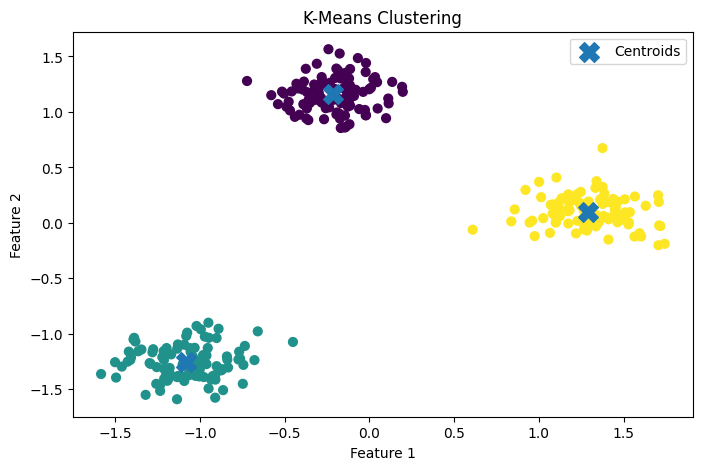

In [ ]:

# K-Means Clustering

# Step 1: Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Step 2: Create a sample dataset
X, y = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=1.0,
    random_state=42
)

# Step 3: Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Apply K-Means Clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)

# Step 5: Get cluster labels and centroids
labels = kmeans.labels_
centroids = kmeans.cluster_centers_

# Step 6: Display results
print("Cluster Labels:")
print(labels)

print("\nCluster Centroids:")
print(centroids)

print("\nInertia:", kmeans.inertia_)

# Step 7: Evaluate clustering
score = silhouette_score(X_scaled, labels)
print("Silhouette Score:", round(score, 3))

# Step 8: Visualize the clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis",
    s=40
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=200,
    label="Centroids"
)

plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()


Dataset loaded successfully!
Dataset shape: (19999, 785)

First five rows:
   6  0  0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  ...  0.581  0.582  0.583  \
0  5  0    0    0    0    0    0    0    0    0  ...      0      0      0   
1  7  0    0    0    0    0    0    0    0    0  ...      0      0      0   
2  9  0    0    0    0    0    0    0    0    0  ...      0      0      0   
3  5  0    0    0    0    0    0    0    0    0  ...      0      0      0   
4  2  0    0    0    0    0    0    0    0    0  ...      0      0      0   

   0.584  0.585  0.586  0.587  0.588  0.589  0.590  
0      0      0      0      0      0      0      0  
1      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0  
3      0      0      0      0      0      0      0  
4      0      0      0      0      0      0      0  

[5 rows x 785 columns]

Features used for clustering:
['6', '0', '0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9', '0.10', '0.11',

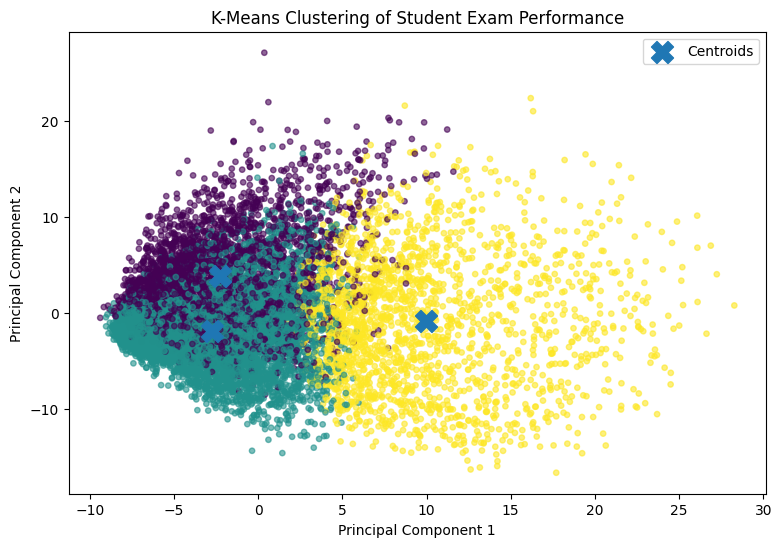

In [ ]:

# K-Means Clustering on Student Exam Performance Dataset

# Step 1: Import required libraries
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Step 2: Find and load the downloaded CSV file
# Define the base directory path (e.g., current directory '.')
path = "."
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

if not csv_files:
    raise FileNotFoundError("No CSV file found in the downloaded dataset folder.")

# Prefer the student exam performance CSV if available
file_path = next(
    (f for f in csv_files
     if "student_exam_performance" in os.path.basename(f).lower()),
    csv_files[0]
)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

# Step 3: Remove ID and outcome columns
# These columns are excluded so clustering is based on student features,
# rather than predefined performance outcomes.
columns_to_drop = [
    col for col in df.columns
    if col.strip().lower() in [
        "student_id",
        "exam_score",
        "pass_status",
        "performance_grade",
        "performance_level"
    ]
]

features_df = df.drop(columns=columns_to_drop, errors="ignore")

# Step 4: Select numerical features
X = features_df.select_dtypes(include=["number", "bool"])

if X.shape[1] < 2:
    raise ValueError("The dataset must contain at least two numerical features.")

print("\nFeatures used for clustering:")
print(X.columns.tolist())

# Step 5: Handle missing values
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

# Step 6: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Step 7: Apply K-Means Clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X_scaled)

# Step 8: Display clustering results
df["Cluster"] = labels

print("\nCluster labels for the first 20 students:")
print(labels[:20])

print("\nNumber of students in each cluster:")
print(pd.Series(labels).value_counts().sort_index())

# Step 9: Display centroids in original feature units
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

centroids_df = pd.DataFrame(
    centroids,
    columns=X.columns
)

print("\nCluster Centroids:")
print(centroids_df.round(2))

# Step 10: Evaluate clustering
score = silhouette_score(
    X_scaled,
    labels,
    sample_size=min(2000, len(X_scaled)),
    random_state=42
)

print("\nInertia:", round(kmeans.inertia_, 2))
print("Silhouette Score:", round(score, 3))

# Step 11: Reduce dimensions for visualization using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

centroids_pca = pca.transform(kmeans.cluster_centers_)

# Sample up to 10,000 points for a readable graph
rng = np.random.RandomState(42)
plot_indices = rng.choice(
    len(X_pca),
    size=min(10000, len(X_pca)),
    replace=False
)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[plot_indices, 0],
    X_pca[plot_indices, 1],
    c=labels[plot_indices],
    cmap="viridis",
    s=15,
    alpha=0.6
)

plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker="X",
    s=250,
    label="Centroids"
)

plt.title("K-Means Clustering of Student Exam Performance")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()
